# INT6163 题目二：网上零售购物篮分析与客户分群

本 Notebook 从 UCI Online Retail II 原始数据一键复现：数据清洗、Apriori 关联规则、RFM 客户分群、群组规则比较、可视化和营销建议。为控制运行时间，默认分析英国客户；将 `USE_UK_ONLY=False` 可扩展到全部国家。

In [1]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn mlxtend openpyxl requests
import io, os, re, time, zipfile, warnings
from pathlib import Path
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
from mlxtend.frequent_patterns import apriori, association_rules
warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 80)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
USE_UK_ONLY = True
DATA_DIR = Path('data'); DATA_DIR.mkdir(exist_ok=True)
XLSX = DATA_DIR / 'online_retail_II.xlsx'
ZIP_URL = 'https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip'
if not XLSX.exists():
    r = requests.get(ZIP_URL, timeout=120); r.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        candidates = [n for n in z.namelist() if n.lower().endswith(('.xlsx', '.xls'))]
        if not candidates: raise FileNotFoundError('下载包中未找到 Excel 文件')
        with z.open(candidates[0]) as src, open(XLSX, 'wb') as dst: dst.write(src.read())
print('数据文件:', XLSX)

Note: you may need to restart the kernel to use updated packages.


数据文件: data/online_retail_II.xlsx


In [2]:
sheets = pd.read_excel(XLSX, sheet_name=None)
raw = pd.concat(sheets.values(), ignore_index=True)
raw.columns = [str(c).strip() for c in raw.columns]
raw['Invoice'] = raw['Invoice'].astype('string').str.strip()
raw['StockCode'] = raw['StockCode'].astype('string').str.strip()
raw['InvoiceDate'] = pd.to_datetime(raw['InvoiceDate'], errors='coerce')
raw['Customer ID'] = pd.to_numeric(raw['Customer ID'], errors='coerce')
raw['Quantity'] = pd.to_numeric(raw['Quantity'], errors='coerce')
raw['Price'] = pd.to_numeric(raw['Price'], errors='coerce')
raw['Country'] = raw['Country'].astype('string').str.strip()
before = len(raw)
steps = []
def drop_and_record(frame, mask, name):
    removed = int(mask.sum()); steps.append((name, removed, len(frame)-removed)); return frame.loc[~mask].copy()
df = drop_and_record(raw, raw['Invoice'].str.startswith('C', na=False), '取消订单')
df = drop_and_record(df, df['Customer ID'].isna(), '缺少 Customer ID')
df = drop_and_record(df, df['Quantity'].isna() | (df['Quantity'] <= 0), '数量<=0或缺失')
df = drop_and_record(df, df['Price'].isna() | (df['Price'] <= 0), '价格<=0或缺失')
valid_code = df['StockCode'].str.fullmatch(r'\d{5}[A-Za-z]?').fillna(False)
df = drop_and_record(df, ~valid_code, '非商品 StockCode')
if USE_UK_ONLY: df = drop_and_record(df, df['Country'].ne('United Kingdom'), '非英国客户')
df['Description'] = df['Description'].fillna('Unknown').astype(str).str.strip().str.upper()
df['Amount'] = df['Quantity'] * df['Price']
print(pd.DataFrame(steps, columns=['清洗步骤','本步剔除','本步后剩余']))
print('原始记录:', before, '；最终记录:', len(df), '；订单数:', df.Invoice.nunique(), '；客户数:', df['Customer ID'].nunique())

             清洗步骤    本步剔除    本步后剩余
0            取消订单   19494  1047877
1  缺少 Customer ID  242257   805620
2        数量<=0或缺失       0   805620
3        价格<=0或缺失      71   805549
4   非商品 StockCode    3990   801559
5           非英国客户   78060   723499
原始记录: 1067371 ；最终记录: 723499 ；订单数: 33360 ；客户数: 5334


## 1. 交易概览

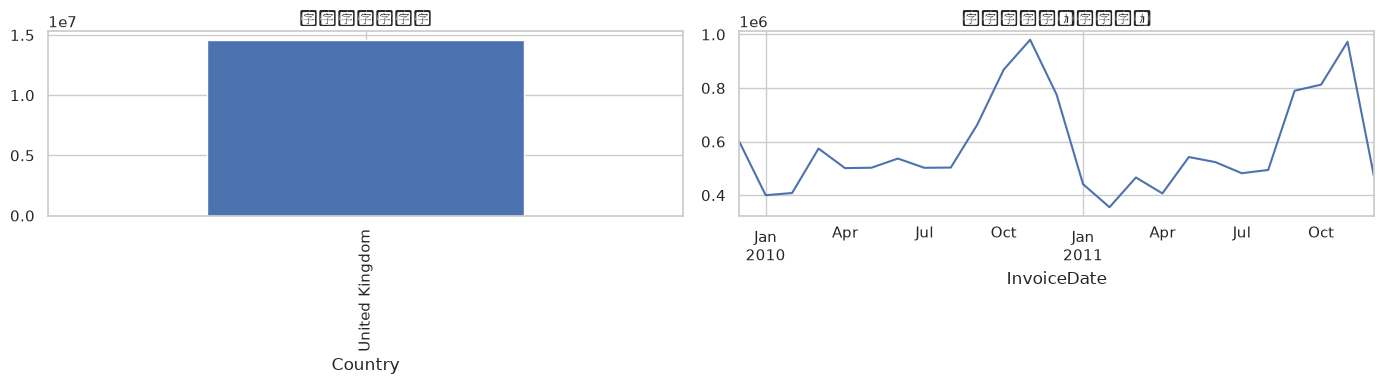

In [3]:
monthly = df.set_index('InvoiceDate').resample('MS')['Amount'].sum()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.groupby('Country')['Amount'].sum().sort_values(ascending=False).head(10).plot.bar(ax=ax[0], title='销售额最高国家')
monthly.plot(ax=ax[1], title='月度销售额（清洗后）')
plt.tight_layout(); plt.show()

## 2. 关联规则

每张发票视为一笔交易，同一商品在同一发票中只计一次。两个支持度阈值用于观察规则数量与运行时间的敏感性；规则按 lift 排序，但最终建议同时考虑 support、confidence、商品销量和可执行性。

In [4]:
basket = (df.groupby(['Invoice','Description'])['Quantity'].sum().unstack(fill_value=0) > 0)
basket = basket.loc[:, basket.sum(axis=0) >= 5]
print('交易-商品矩阵:', basket.shape)
def mine_rules(transactions, min_support):
    start = time.perf_counter()
    freq = apriori(transactions, min_support=min_support, use_colnames=True, low_memory=True)
    rules = association_rules(freq, metric='lift', min_threshold=1.0)
    rules = rules[(rules['confidence'] >= .2) & (rules['lift'] > 1)]
    rules = rules.sort_values(['lift','confidence','support'], ascending=False).reset_index(drop=True)
    return freq, rules, time.perf_counter()-start
rule_runs = {}
for s in [.02, .01]:
    freq, rules, seconds = mine_rules(basket, s)
    rule_runs[s] = (freq, rules, seconds)
    print(f'min_support={s}: 频繁项集={len(freq)}, 规则={len(rules)}, 用时={seconds:.2f}s')
rules = rule_runs[.02][1]
def fmt_itemset(x): return ', '.join(sorted(x))
top10 = rules.head(10).copy()
top10['antecedents'] = top10['antecedents'].map(fmt_itemset)
top10['consequents'] = top10['consequents'].map(fmt_itemset)
display(top10[['antecedents','consequents','support','confidence','lift']].round(4))

交易-商品矩阵: (33360, 4578)


min_support=0.02: 频繁项集=181, 规则=18, 用时=0.25s


min_support=0.01: 频繁项集=713, 规则=350, 用时=0.61s


,antecedents,consequents,support,confidence,lift
0,SWEETHEART CERAMIC TRINKET BOX,STRAWBERRY CERAMIC TRINKET BOX,0.0227,0.6892,13.8745
1,STRAWBERRY CERAMIC TRINKET BOX,SWEETHEART CERAMIC TRINKET BOX,0.0227,0.4562,13.8745
2,WOODEN FRAME ANTIQUE WHITE,WOODEN PICTURE FRAME WHITE FINISH,0.0291,0.5654,11.7090
3,WOODEN PICTURE FRAME WHITE FINISH,WOODEN FRAME ANTIQUE WHITE,0.0291,0.6034,11.7090
4,HOME BUILDING BLOCK WORD,LOVE BUILDING BLOCK WORD,0.0229,0.4321,9.9694
5,LOVE BUILDING BLOCK WORD,HOME BUILDING BLOCK WORD,0.0229,0.5284,9.9694
6,HEART OF WICKER LARGE,HEART OF WICKER SMALL,0.0256,0.4968,9.5800
7,HEART OF WICKER SMALL,HEART OF WICKER LARGE,0.0256,0.4942,9.5800
8,LUNCH BAG BLACK SKULL.,LUNCH BAG SPACEBOY DESIGN,0.0219,0.3843,7.6363
9,LUNCH BAG SPACEBOY DESIGN,LUNCH BAG BLACK SKULL.,0.0219,0.4354,7.6363


解释：support 是同时出现该前件和后件的交易占比；confidence 是买前件的交易中买后件的比例；lift 是该比例相对于后件自然购买率的倍数。lift 高但 support 极低的规则可能只是偶然组合，不能直接作为营销方案。相同系列、颜色或尺寸的商品规则也可能是平凡关系，应先检查商品描述后再决定是否使用。

## 3. RFM 客户分群

,K,inertia,silhouette
0,2,7728.584,0.441
1,3,5685.770,0.352
2,4,4385.331,0.370
3,5,3652.242,0.346
4,6,3156.386,0.342
5,7,2833.927,0.325
6,8,2551.607,0.302


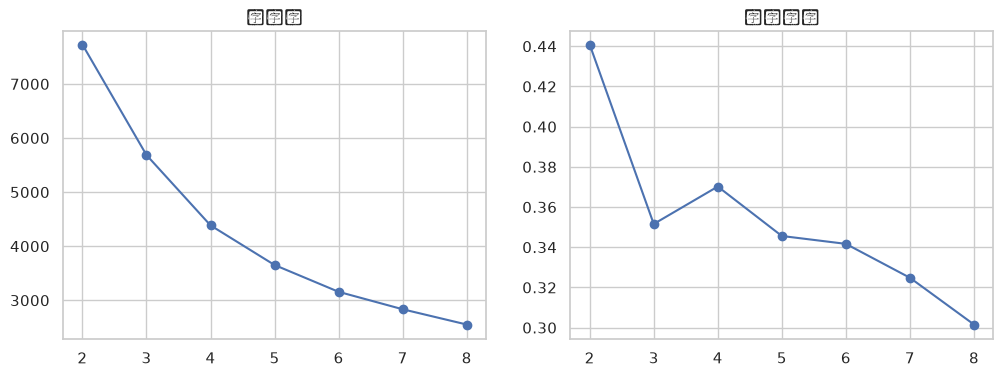

,客户数,Recency,Frequency,Monetary,收入贡献
cluster,,,,,
1,2141,52.08,12.47,5939.94,12717421.86
0,3193,303.48,2.09,580.73,1854257.77


,客户数,Recency,Frequency,Monetary,收入贡献,客户群
cluster,,,,,,
1,2141,52.08,12.47,5939.94,12717421.86,高价值忠诚客户
0,3193,303.48,2.09,580.73,1854257.77,低价值/新客户


In [5]:
snapshot = df['InvoiceDate'].max() + pd.Timedelta(days=1)
rfm = df.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('Amount', 'sum')).reset_index()
rfm = rfm[(rfm['Monetary'] > 0) & (rfm['Frequency'] > 0)].copy()
rfm_model = np.log1p(rfm[['Recency','Frequency','Monetary']])
Z = StandardScaler().fit_transform(rfm_model)
scores = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z)
    scores.append((k, km.inertia_, silhouette_score(Z, km.labels_)))
scores = pd.DataFrame(scores, columns=['K','inertia','silhouette'])
display(scores.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4)); ax[0].plot(scores.K,scores.inertia,'o-'); ax[0].set_title('肘部法'); ax[1].plot(scores.K,scores.silhouette,'o-'); ax[1].set_title('轮廓系数'); plt.show()
K = int(scores.loc[scores.silhouette.idxmax(),'K'])
km = KMeans(n_clusters=K, n_init=30, random_state=RANDOM_STATE).fit(Z)
rfm['cluster'] = km.labels_
profile = rfm.groupby('cluster').agg(客户数=('Customer ID','size'), Recency=('Recency','mean'), Frequency=('Frequency','mean'), Monetary=('Monetary','mean'), 收入贡献=('Monetary','sum')).sort_values('Monetary', ascending=False)
display(profile.round(2))
names = {}
for c, row in profile.iterrows():
    if row.Recency <= profile.Recency.median() and row.Frequency >= profile.Frequency.median() and row.Monetary >= profile.Monetary.median(): names[c] = '高价值忠诚客户'
    elif row.Recency > profile.Recency.median() and row.Frequency >= profile.Frequency.median(): names[c] = '高频但有流失风险'
    elif row.Monetary < profile.Monetary.median(): names[c] = '低价值/新客户'
    else: names[c] = '一般客户'
rfm['segment'] = rfm.cluster.map(names)
profile['客户群'] = profile.index.map(names)
display(profile.round(2))

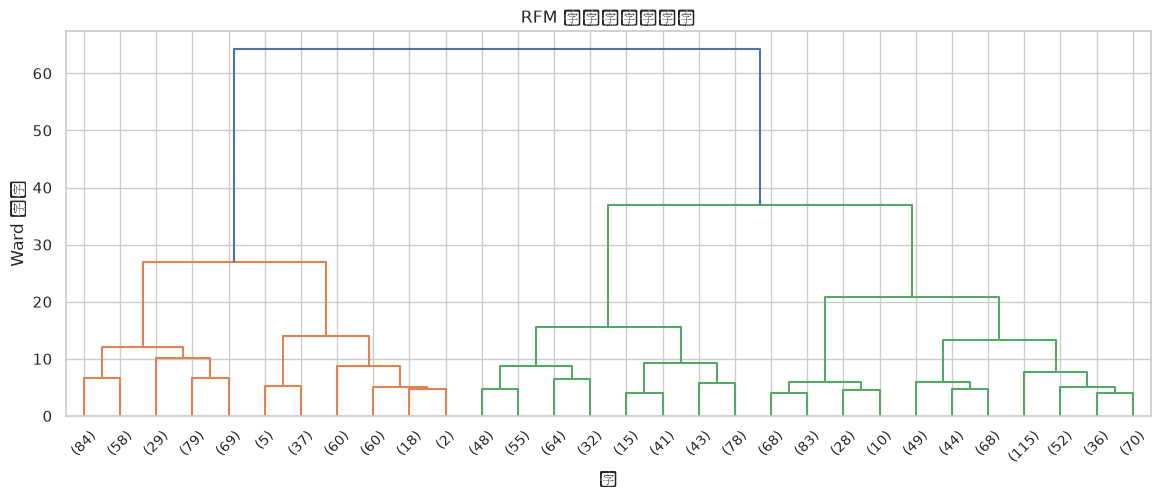

K-means 与层次聚类在客户标签上的 ARI 可用 sklearn.metrics.adjusted_rand_score 计算；树状图用于检查是否存在相近的合并层次。


In [6]:
sample = Z[np.random.default_rng(RANDOM_STATE).choice(len(Z), size=min(1500,len(Z)), replace=False)]
link = linkage(sample, method='ward')
plt.figure(figsize=(14, 5)); dendrogram(link, truncate_mode='lastp', p=30, show_leaf_counts=True); plt.title('RFM 层次聚类树状图'); plt.xlabel('簇'); plt.ylabel('Ward 距离'); plt.show()
hc = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(Z)
print('K-means 与层次聚类在客户标签上的 ARI 可用 sklearn.metrics.adjusted_rand_score 计算；树状图用于检查是否存在相近的合并层次。')

## 4. 不同客户群的购物篮规则

In [7]:
invoice_segment = df[['Invoice','Customer ID']].drop_duplicates().merge(rfm[['Customer ID','segment']], on='Customer ID', how='inner')
df_seg = df.merge(invoice_segment[['Invoice','segment']], on='Invoice', how='inner')
segment_rules = {}
for segment in rfm['segment'].value_counts().head(3).index:
    inv = df_seg.loc[df_seg.segment.eq(segment), 'Invoice'].unique()
    b = (df_seg[df_seg.Invoice.isin(inv)].groupby(['Invoice','Description'])['Quantity'].sum().unstack(fill_value=0) > 0)
    b = b.loc[:, b.sum() >= max(3, int(.01*len(b)))]
    if len(b) < 10 or b.shape[1] < 2: continue
    f, r, sec = mine_rules(b, .02)
    segment_rules[segment] = r
    print('\n', segment, '交易数=', len(b), '规则数=', len(r))
    if len(r):
        out=r.head(5).copy(); out['antecedents']=out.antecedents.map(fmt_itemset); out['consequents']=out.consequents.map(fmt_itemset)
        display(out[['antecedents','consequents','support','confidence','lift']].round(4))


 低价值/新客户 交易数= 6668 规则数= 8


,antecedents,consequents,support,confidence,lift
0,HOME BUILDING BLOCK WORD,LOVE BUILDING BLOCK WORD,0.0208,0.4929,12.1730
1,LOVE BUILDING BLOCK WORD,HOME BUILDING BLOCK WORD,0.0208,0.5148,12.1730
2,BAKING SET SPACEBOY DESIGN,BAKING SET 9 PIECE RETROSPOT,0.0202,0.6683,10.4364
3,BAKING SET 9 PIECE RETROSPOT,BAKING SET SPACEBOY DESIGN,0.0202,0.3162,10.4364
4,HEART OF WICKER SMALL,HEART OF WICKER LARGE,0.0234,0.4727,8.8049



 高价值忠诚客户 交易数= 26692 规则数= 42


,antecedents,consequents,support,confidence,lift
0,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.0204,0.8035,28.1843
1,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.0204,0.7148,28.1843
2,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN,0.0211,0.6218,19.9015
3,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.0211,0.6763,19.9015
4,SWEETHEART CERAMIC TRINKET BOX,STRAWBERRY CERAMIC TRINKET BOX,0.0236,0.6977,13.8869


## 5. 结论与可执行建议

1. 不把最高 lift 单独当作商业价值：优先筛选同时具有足够 support、confidence、利润空间和库存可得性的规则，并用 A/B 测试验证增量销售。
2. 对高价值忠诚客户，使用高 support 的组合做个性化推荐和套装；避免过度折扣，保护毛利。
3. 对“高频但有流失风险”客户，按最近购买日期设置唤回窗口，推荐其历史组合中的互补商品，并提供有限期限优惠。
4. 对低价值或新客户，采用低门槛组合、免邮门槛和首购后的第二单推荐，提高 Frequency。
5. 批发客户、圣诞季节性、两年观察窗口和缺失客户 ID 会影响结论；应按月份/季节复核规则，并把批发客户与零售客户分层。客户画像只用于推荐和资源配置，不应出售或推断敏感属性。